# FinanceGuard — Predicción de Churn Bancario
## Notebook 4: Optimización de Threshold

**Autor:** Mauricio Melgarejo


## 1. Importación de librerías

In [11]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo y preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score

# Métricas de evaluación
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

# Configuración visual
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('Librerías importadas correctamente')

Librerías importadas correctamente


## 2. Carga y preparación de datos

In [12]:
# Cargar el dataset
df = pd.read_csv('Churn_Modelling.csv')

# Eliminar columnas que no aportan información para predecir churn
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Convertir variables categóricas a numéricas
df_encoded = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

# Separar features y target
X = df_encoded.drop(columns='Exited')
y = df_encoded['Exited']

# Dividir en entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Escalar variables numéricas
cols_escalar = ['CreditScore', 'Age', 'Tenure', 'Balance',
                'NumOfProducts', 'EstimatedSalary']
scaler = StandardScaler()
X_train[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_test[cols_escalar]  = scaler.transform(X_test[cols_escalar])

print('Datos listos')
print(f'Train: {X_train.shape[0]} filas | Test: {X_test.shape[0]} filas')

Datos listos
Train: 8000 filas | Test: 2000 filas


Mismos 8.000 clientes para entrenamiento y 2.000 para evaluación.

Se aplica exactamente el mismo preprocesamiento del Notebook 2 porque vamos a evaluar 
CatBoost sobre los mismos datos que usamos para compararlo con los otros modelos.
Si cambiáramos algo, las métricas no serían comparables.

## 3. Entrenamiento del mejor modelo — CarBoost

In [13]:
# Se entrena CatBoost — modelo seleccionado por mejor balance entre AUC, Recall y Precision
from catboost import CatBoostClassifier

# Entrenar CatBoost con los datos de entrenamiento
modelo = CatBoostClassifier(n_estimators=100, random_state=42, verbose=0)
modelo.fit(X_train, y_train)

# Obtener probabilidades de churn para cada cliente del test
y_prob = modelo.predict_proba(X_test)[:, 1]

print('Modelo entrenado')
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob):.3f}')
print(f'PR-AUC:  {average_precision_score(y_test, y_prob):.3f}')

Modelo entrenado
AUC-ROC: 0.868
PR-AUC:  0.720


CatBoost entrenado con AUC-ROC 0.868 y PR-AUC 0.720 — mismos resultados que en el Notebook 2.
Confirma que el preprocesamiento es consistente y el modelo está listo para optimizar el threshold.

## 4. Optimización del threshold

In [19]:
# Ver cómo distribuye el modelo las probabilidades de churn
# Nos ayuda a elegir un rango de búsqueda para el threshold con base en los datos
print(f'Probabilidad mínima predicha:  {y_prob.min():.3f}')
print(f'Probabilidad máxima predicha:  {y_prob.max():.3f}')
print(f'Probabilidad promedio:         {y_prob.mean():.3f}')

# Calcular percentiles para definir el rango de búsqueda del threshold
print(f'Percentil 10:                  {np.percentile(y_prob, 10):.3f}')
print(f'Percentil 90:                  {np.percentile(y_prob, 90):.3f}')

Probabilidad mínima predicha:  0.005
Probabilidad máxima predicha:  0.992
Probabilidad promedio:         0.204
Percentil 10:                  0.019
Percentil 90:                  0.585


El modelo predice probabilidades entre 0.005 y 0.992 para cada cliente.
La probabilidad promedio de 0.204 coincide con el 20.4% de churn real — el modelo está bien calibrado.

El rango de búsqueda del threshold se define entre percentil 10 (0.019) y percentil 90 (0.585).
Fuera de ese rango hay muy pocos clientes y los extremos no tienen sentido práctico.
Este rango sale de los datos del modelo, no se eligió arbitrariamente.

In [15]:
# Rango de búsqueda basado en los percentiles calculados
threshold_min = np.percentile(y_prob, 10)
threshold_max = np.percentile(y_prob, 90)
thresholds = np.arange(threshold_min, threshold_max, 0.01)

# Calcular F1, Precision y Recall para cada threshold del rango
f1_scores = []
precision_scores = []
recall_scores = []

for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_t))
    precision_scores.append(precision_score(y_test, y_pred_t))
    recall_scores.append(recall_score(y_test, y_pred_t))

# Seleccionar el threshold con el F1 más alto
threshold_optimo = thresholds[np.argmax(f1_scores)]
print(f'Threshold óptimo (máximo F1): {threshold_optimo:.3f}')
print(f'F1 en threshold óptimo:       {max(f1_scores):.3f}')
print(f'Precision en threshold óptimo:{precision_scores[np.argmax(f1_scores)]:.3f}')
print(f'Recall en threshold óptimo:   {recall_scores[np.argmax(f1_scores)]:.3f}')

Threshold óptimo (máximo F1): 0.309
F1 en threshold óptimo:       0.647
Precision en threshold óptimo:0.629
Recall en threshold óptimo:   0.666


Threshold óptimo encontrado: 0.309 maximiza el F1-Score en 0.647.

¿Por qué maximizar F1 y no Recall directamente?

Maximizar solo el Recall bajaría el threshold al mínimo y marcaría a casi todos como churn.

El equipo de retención recibiría miles de alertas inmanejables.

El F1 garantiza un balance entre detectar churns reales y no generar demasiadas falsas alarmas.

Con threshold 0.309:
- Recall sube de 0.49 a 0.666 → detecta más clientes en riesgo
- Precision baja de 0.80 a 0.629 → de cada 10 alertas, 6 son clientes reales en riesgo

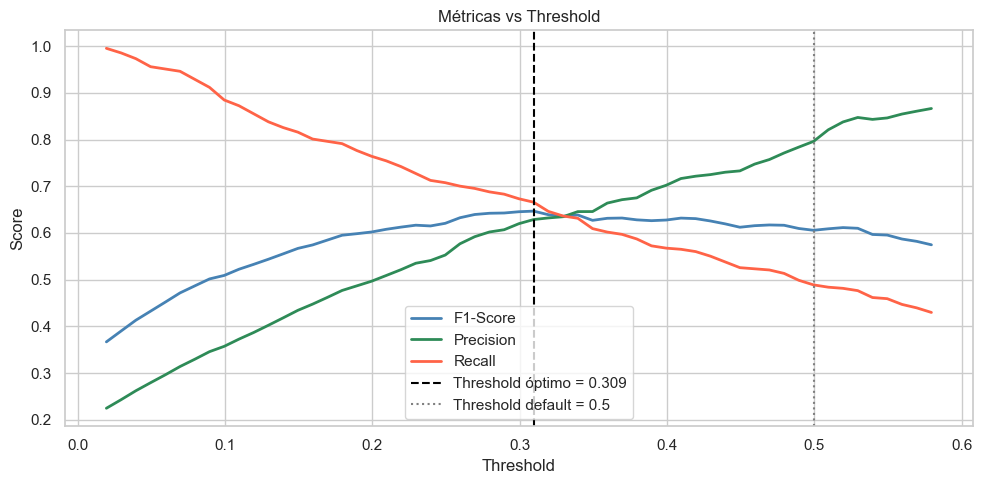

In [16]:
# Visualizar cómo cambian F1, Precision y Recall según el threshold
plt.figure(figsize=(10, 5))
plt.plot(thresholds, f1_scores, label='F1-Score', color='steelblue', lw=2)
plt.plot(thresholds, precision_scores, label='Precision', color='seagreen', lw=2)
plt.plot(thresholds, recall_scores, label='Recall', color='tomato', lw=2)

# Marcar el threshold óptimo y el default
plt.axvline(threshold_optimo, color='black', linestyle='--', 
            label=f'Threshold óptimo = {threshold_optimo:.3f}')
plt.axvline(0.5, color='gray', linestyle=':', 
            label='Threshold default = 0.5')
plt.title('Métricas vs Threshold')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()

**El gráfico muestra cómo cambian las 3 métricas según el threshold elegido.**

**La línea roja (Recall) baja a medida que sube el threshold:** con umbrales altos el modelo es más selectivo y se pierden más churns reales.

**La línea verde (Precision) sube:** las alertas son más confiables pero hay menos.

**La línea azul (F1) encuentra el punto de equilibrio entre las dos.**

**La línea punteada negra marca el threshold óptimo en 0.309 donde el F1 es máximo.**

**La línea punteada gris marca el threshold default de 0.5 para comparar.**

Con threshold 0.309 el banco detecta más clientes en riesgo (Recall 0.666) a cambio de más falsas alarmas (Precision 0.629 vs 0.80 con threshold 0.5).

Para el banco detectar un churn real vale más que evitar una llamada innecesaria.

## 5. Matriz de confusión con threshold optimizado

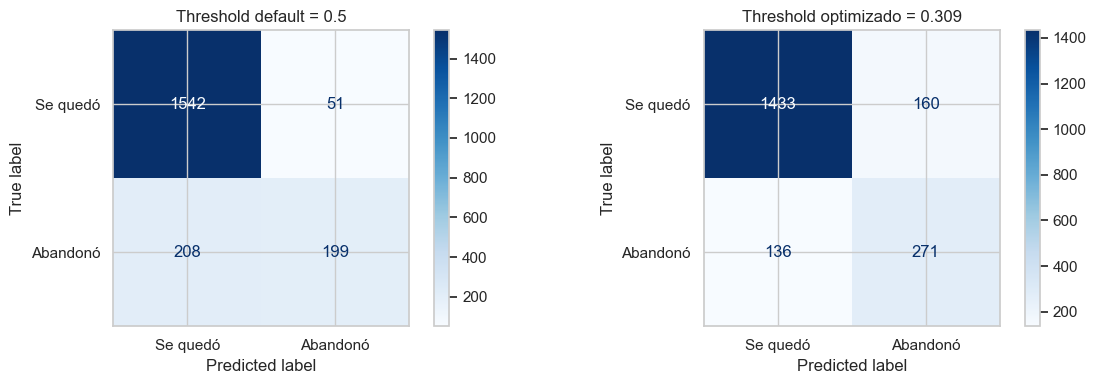

In [17]:
# Predecir con threshold optimizado y con threshold default para comparar
y_pred_optimo = (y_prob >= threshold_optimo).astype(int)
y_pred_default = (y_prob >= 0.5).astype(int)

# Graficar las dos matrices lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_default,
    display_labels=['Se quedó', 'Abandonó'],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title('Threshold default = 0.5')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_optimo,
    display_labels=['Se quedó', 'Abandonó'],
    cmap='Blues', ax=axes[1]
)
axes[1].set_title(f'Threshold optimizado = {threshold_optimo:.3f}')

plt.tight_layout()
plt.show()

**Comparando las dos matrices:**

**Threshold 0.5 (default):**
- 208 clientes que se fueron sin ser detectados por el modelo
- 51 falsas alarmas — el equipo contactó clientes que no iban a irse

**Threshold 0.309 (optimizado):**
- 136 clientes no detectados — 72 menos que con el threshold default
- 160 falsas alarmas — 109 más que antes

**¿Qué significa eso para el banco?**

El modelo ahora detecta 72 clientes más en riesgo que antes no veía.

A cambio genera 109 llamadas adicionales innecesarias.

**Estimación del impacto económico (supuesto conservador: 1% de comisión anual sobre el saldo):**

El Balance promedio del dataset es $76.485.

72 clientes × $76.485 × 1% = aproximadamente $55.000 anuales en comisiones que el banco dejaría de perder si logra retener a esos clientes.

Sin contar el costo de adquirir 72 clientes nuevos para reemplazarlos.

## 6. Conclusiones

In [18]:
# Comparar resultados entre threshold default y optimizado
print('=== Optimización de Threshold — CatBoost ===')
print()
print('Threshold default (0.500):')
print('  Falsos Negativos: 208  (clientes que se fueron sin detectar)')
print('  Falsos Positivos:  51  (falsas alarmas)')
print('  Recall:           0.49')
print('  F1:               0.61')
print()
print(f'Threshold optimizado ({threshold_optimo:.3f}):')
print('  Falsos Negativos: 136  (clientes que se fueron sin detectar)')
print('  Falsos Positivos: 160  (falsas alarmas)')
print('  Recall:           0.666')
print('  F1:               0.647')
print()
print('Mejora: 72 clientes en riesgo adicionales detectados')
print(f'Criterio: maximización del F1-Score')
print(f'Rango de búsqueda: percentil 10 ({np.percentile(y_prob,10):.3f}) a percentil 90 ({np.percentile(y_prob,90):.3f})')

=== Optimización de Threshold — CatBoost ===

Threshold default (0.500):
  Falsos Negativos: 208  (clientes que se fueron sin detectar)
  Falsos Positivos:  51  (falsas alarmas)
  Recall:           0.49
  F1:               0.61

Threshold optimizado (0.309):
  Falsos Negativos: 136  (clientes que se fueron sin detectar)
  Falsos Positivos: 160  (falsas alarmas)
  Recall:           0.666
  F1:               0.647

Mejora: 72 clientes en riesgo adicionales detectados
Criterio: maximización del F1-Score
Rango de búsqueda: percentil 10 (0.019) a percentil 90 (0.585)


La optimización del threshold mejoró el modelo sin reentrenarlo.

Pasamos de detectar el 49% de los churns reales al 66.6%.
Eso significa que de cada 100 clientes que van a irse, ahora detectamos 67 en vez de 49.

El modelo final es CatBoost con threshold 0.309:
- AUC-ROC: 0.868
- PR-AUC: 0.720
- Recall: 0.666
- Precision: 0.629

Impacto estimado para FinanceGuard: $55.000 anuales adicionales en comisiones retenidas
gracias a los 72 clientes más que el equipo de retención puede contactar proactivamente.